In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from random import randrange
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import scale
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn import metrics
from sklearn.model_selection import ParameterGrid
from sklearn.cluster import KMeans
import sys
import time
from time import time
import pyarrow

## Silhouette Scores For Flow Logs
A notebook to compute silhouette scores and identify the best k. Part of the DUNE project (https://github.com/opendr-io/dune) and useful for hunting threats that are resistant to conventional detection or just hunting at great scale. This instance is set up for VPC flow logs.


In [2]:
# input file -- the same aggregated flow-log parquet pyod-vflows.ipynb reads (its cell 3)
PARQUET_PATH = "vflowsAgg-637602092272-november-2026.parquet"

# Distinct-rows mode, as pyod-vflows' PYOD_DISTINCT: cluster each distinct combination of the
# fields (a few thousand) instead of every session (millions), with a log_count column saying
# how many sessions share it. Without it, a few very common combinations fill the silhouette
# sample with identical points, and the score just climbs with k. False = every session.
DISTINCT = True
# log_count = log10(sessions with that combination), capped at log10(COUNT_CAP): rare
# combinations spread out at the low end, and everything seen COUNT_CAP or more times looks
# equally common (as PYOD_COUNT_CAP).
COUNT_CAP = 100


In [3]:
# Read the file. Drop NODATA / SKIPDATA records (log-status), as pyod-vflows does: no
# addresses, ports, protocol or traffic -- every field empty, which would form its own
# cluster of empty rows.
raw = pd.read_parquet(PARQUET_PATH)
if "log-status" in raw.columns:
    _empty = raw["log-status"].isin(["NODATA", "SKIPDATA"])
    print(f"dropped {int(_empty.sum()):,} NODATA / SKIPDATA rows, {int((~_empty).sum()):,} left")
    raw = raw[~_empty].reset_index(drop=True)
print('raw data shape and column names:')
print(raw.shape)
sdf = raw.copy()


dropped 6,682 NODATA / SKIPDATA rows, 3,616,571 left


raw data shape and column names:
(3616571, 29)


In [4]:
# Cardinality of the fields listed below -- the same CARD_FIELDS as pyod-vflows (its cell 4).
# Edit the list: comment a line out to skip that field. A name raw doesn't have is reported
# and skipped. Shows distinct values, share of rows that are distinct, nulls, dtype, and a
# few examples -- sorted by distinct values, highest first.
CARD_FIELDS = [
    "interface-id",
    "protocol",
    "action",
    "tag-direction",
    "tag-country",
    "tag-service"
]

_missing = [c for c in CARD_FIELDS if c not in raw.columns]
if _missing:
    print(f"!! not in raw, skipped: {_missing}")
_cf = [c for c in dict.fromkeys(CARD_FIELDS) if c in raw.columns]

_n = len(raw)
cardinality = pd.DataFrame({
    "distinct": [raw[c].nunique(dropna=True) for c in _cf],
    "nulls":    [int(raw[c].isna().sum()) for c in _cf],
    "dtype":    [str(raw[c].dtype) for c in _cf],
    "examples": [", ".join(map(str, raw[c].dropna().unique()[:3])) for c in _cf],
}, index=pd.Index(_cf, name="field"))
cardinality.insert(1, "distinct_pct", cardinality["distinct"] / max(_n, 1))
cardinality = cardinality.sort_values("distinct", ascending=False)

print(f"{_n:,} rows, {len(_cf)} fields")
cardinality.style.format({"distinct": "{:,}", "nulls": "{:,}", "distinct_pct": "{:.2%}"})


3,616,571 rows, 6 fields


,distinct,distinct_pct,nulls,dtype,examples
field,,,,,
tag-country,220,0.01%,10,string,"United States, Seychelles, China"
tag-service,41,0.00%,"2,200,941",string,"HTTPS, SMB, SSH"
interface-id,12,0.00%,0,object,"eni-02b85e2a3caf5dd60, eni-0f324b6f6044e4ef3, eni-0a98cf7cabe3677e3"
protocol,7,0.00%,0,Int64,"6, 17, 1"
tag-direction,2,0.00%,0,string,"north-south, east-west"
action,2,0.00%,0,object,"ACCEPT, REJECT"


In [5]:
# Select fields to encode and use for clustering: both take CARD_FIELDS from the cell above
# (names raw doesn't have are left out), as pyod-vflows' cell 5 does. Copies, so editing one
# list here doesn't change the other or CARD_FIELDS.
# Warns about any field with more than MAX_CARDINALITY distinct values -- as category codes,
# high-cardinality fields (addresses, ports, timestamps) give arbitrary numbers that KMeans
# treats as distances.
fields_to_encode     = [c for c in CARD_FIELDS if c in raw.columns]
columns_for_outliers = list(fields_to_encode)
print(f"{len(columns_for_outliers)} fields: {', '.join(columns_for_outliers)}")

MAX_CARDINALITY = 1000
_hiCard = {c: n for c in fields_to_encode if (n := raw[c].nunique()) > MAX_CARDINALITY}
for _c, _n in sorted(_hiCard.items(), key=lambda kv: -kv[1]):
    print(f"!! {_c}: {_n:,} distinct values (> {MAX_CARDINALITY:,})")


6 fields: interface-id, protocol, action, tag-direction, tag-country, tag-service


In [6]:
# print statistical summary, useful in assesing balance 
for field in fields_to_encode:
    print(field)
    print(sdf[field].value_counts().describe())
    print("==============")

interface-id
count    1.200000e+01
mean     3.013809e+05
std      5.518763e+05
min      1.500000e+01
25%      2.642500e+02
50%      9.044450e+04
75%      2.928768e+05
max      1.892358e+06
Name: count, dtype: float64
protocol
count               7.0
mean           516653.0
std      1226215.212137
min                 2.0
25%                 6.5
50%               671.0
75%            165626.0
max           3284633.0
Name: count, dtype: Float64
action
count    2.000000e+00
mean     1.808286e+06
std      1.052140e+06
min      1.064310e+06
25%      1.436298e+06
50%      1.808286e+06
75%      2.180273e+06
max      2.552261e+06
Name: count, dtype: float64
tag-direction


count               2.0
mean          1808285.5
std      2557287.736607
min                10.0
25%           904147.75
50%           1808285.5
75%          2712423.25
max           3616561.0
Name: count, dtype: Float64
tag-country


count           220.0
mean     16438.913636
std      97615.169293
min               1.0
25%             18.75
50%             160.0
75%            1517.0
max         1315980.0
Name: count, dtype: Float64
tag-service
count             41.0
mean      34527.560976
std      102853.218285
min                2.0
25%             1137.0
50%             2490.0
75%            10757.0
max           466764.0
Name: count, dtype: Float64


In [7]:
#convert to categorical type and then to integers 
for field in fields_to_encode:
    sdf[field] = sdf[field].astype('category')
    sdf[field] = sdf[field].cat.codes

In [8]:
#remove the mean and scale each feature/variable to unit variance
x = sdf.loc[:, columns_for_outliers].values
# Standardizing the features
x = StandardScaler().fit_transform(x)

In [9]:
pca_2 = PCA(n_components=2)
X2 = pca_2.fit_transform(x)
#reduce dimensionality of the data so we can plot it

In [10]:
# The rows to cluster. DISTINCT (cell 2): one row per distinct combination of
# fields_to_encode, plus log_count as the last column (as pyod-vflows' PX); combos has each
# row's combination and its session count. Otherwise one row per session.
if DISTINCT:
    combos = sdf[fields_to_encode].value_counts().rename("sessions").reset_index()
    sil_rows = combos[fields_to_encode].copy()
    sil_rows["log_count"] = np.log10(np.minimum(combos["sessions"], COUNT_CAP))
    print(f"{len(combos):,} distinct combinations of {len(fields_to_encode)} fields in {len(sdf):,} sessions; "
          f"sessions per combination: median {int(combos['sessions'].median()):,}, "
          f"max {int(combos['sessions'].max()):,}; "
          f"{int((combos['sessions'] < COUNT_CAP).sum()):,} below the cap of {COUNT_CAP:,}")
else:
    combos = None
    sil_rows = sdf[fields_to_encode].copy()
    print(f"{len(sil_rows):,} sessions x {sil_rows.shape[1]} fields")

# scale numerical data in a pandas DataFrame using the StandardScaler 
sdf_scaled = sil_rows.copy()
sdf_scaled[sdf_scaled.columns] = StandardScaler().fit_transform(sdf_scaled)
print(sdf_scaled.describe())

# creates a PCA object configured to reduce the dataset to two dimensions. 
# The parameter n_components=2 keeps the two most significant
# principal components.

pca_2 = PCA(n_components=2)
pca_2_result = pca_2.fit_transform(sdf_scaled)
print('Explained variation per principal component: {}'.format(pca_2.explained_variance_ratio_))
print('Cumulative variance explained by 2 principal components: {:.2%}'.format(
    np.sum(pca_2.explained_variance_ratio_)))

# Results from pca.components_
# create a new DataFrame, dataset_pca, from the absolute values
# of the components_ attribute of the pca_2 object. 
# The rows of this DataFrame correspond to the principal components (PC_1 and PC_2),
# and the columns correspond to the original features from sdf_scaled.
dataset_pca = pd.DataFrame(abs(pca_2.components_), columns=sdf_scaled.columns, index=['PC_1', 'PC_2'])

print('\n\n', dataset_pca)
# filter the components, retaining only those loadings that are greater
# than 0.3, indicating a substantial contribution to the variance captured 
# by the principal component.iloc[0] and .iloc[1] are used to select 
# the respective rows for PC_1 and PC_2. dropna() is applied to remove any 
# features that do not meet the threshold, simplifying the output to only
# include relevant features.
print("\n*************** Most important features *************************")
print('As per PC 1:\n', (dataset_pca[dataset_pca > 0.3].iloc[0]).dropna())
print('\n\nAs per PC 2:\n', (dataset_pca[dataset_pca > 0.3].iloc[1]).dropna())
print("\n******************************************************************")

9,230 distinct combinations of 6 fields in 3,616,571 sessions; sessions per combination: median 5, max 344,126; 8,189 below the cap of 100
       interface-id      protocol        action  tag-direction   tag-country  \
count  9.230000e+03  9.230000e+03  9.230000e+03   9.230000e+03  9.230000e+03   
mean  -1.693601e-17 -3.491128e-16  2.586591e-16   1.208615e-15 -6.158550e-17   
std    1.000054e+00  1.000054e+00  1.000054e+00   1.000054e+00  1.000054e+00   
min   -1.357565e+00 -3.681639e+00 -4.760952e+00  -4.802603e+01 -1.939245e+00   
25%   -1.121433e+00 -1.934920e-01  2.100420e-01   2.082204e-02 -8.255781e-01   
50%   -1.769068e-01 -1.934920e-01  2.100420e-01   2.082204e-02  5.280711e-02   
75%    1.003751e+00 -1.934920e-01  2.100420e-01   2.082204e-02  8.370796e-01   
max    1.239883e+00  6.782802e+00  2.100420e-01   2.082204e-02  1.511554e+00   

        tag-service     log_count  
count  9.230000e+03  9.230000e+03  
mean   1.016161e-16 -1.478052e-16  
std    1.000054e+00  1.000054e+0

In [11]:
sdf_scaled

,interface-id,protocol,action,tag-direction,tag-country,tag-service,log_count
0,-1.121433,-0.193492,-4.760952,0.020822,1.339014,-0.733585,1.726100
1,-1.121433,-0.193492,0.210042,0.020822,1.339014,-1.387233,1.726100
2,-1.121433,-0.193492,0.210042,0.020822,0.664540,-1.387233,1.726100
3,1.003751,-0.193492,0.210042,0.020822,1.339014,-1.387233,1.726100
4,-1.121433,-0.193492,-4.760952,0.020822,1.339014,1.154730,1.726100
...,...,...,...,...,...,...,...
9225,-1.357565,-0.193492,0.210042,0.020822,-1.735334,-0.733585,-1.167659
9226,-0.176907,-0.193492,0.210042,0.020822,1.417441,-0.806213,-1.167659
9227,-1.357565,-0.193492,0.210042,0.020822,-1.719649,-1.387233,-1.167659
9228,-1.357565,-0.193492,0.210042,0.020822,-1.719649,-0.806213,-1.167659


In [12]:
print(dataset_pca)

      interface-id  protocol    action  tag-direction  tag-country  \
PC_1      0.433157  0.022515  0.656559       0.030758     0.240566   
PC_2      0.405102  0.299189  0.146020       0.303697     0.600658   

      tag-service  log_count  
PC_1     0.228438   0.519418  
PC_2     0.337499   0.397653  


Parameter: {'n_clusters': 2} Score 0.5320310550345193
Parameter: {'n_clusters': 3} Score 0.17426960691551804
Parameter: {'n_clusters': 4} Score 0.2073323273776748


Parameter: {'n_clusters': 5} Score 0.19219191293106047
Parameter: {'n_clusters': 6} Score 0.20692834715780556


Parameter: {'n_clusters': 7} Score 0.2061874330489108
Parameter: {'n_clusters': 8} Score 0.2232470134297073


Parameter: {'n_clusters': 9} Score 0.22286915607908422
Parameter: {'n_clusters': 10} Score 0.23397551124046406


Parameter: {'n_clusters': 11} Score 0.2241990547884637
Parameter: {'n_clusters': 12} Score 0.23572641579747292


Parameter: {'n_clusters': 13} Score 0.2337453365757347
Parameter: {'n_clusters': 14} Score 0.243137094694448


... (6 outputs left out)

Parameter: {'n_clusters': 26} Score 0.2764210519697954
Parameter: {'n_clusters': 27} Score 0.27307960980382767


Parameter: {'n_clusters': 28} Score 0.26910879091471973


Parameter: {'n_clusters': 29} Score 0.26953955869318097
Parameter: {'n_clusters': 30} Score 0.26686934204539736


Parameter: {'n_clusters': 31} Score 0.2669127673645003


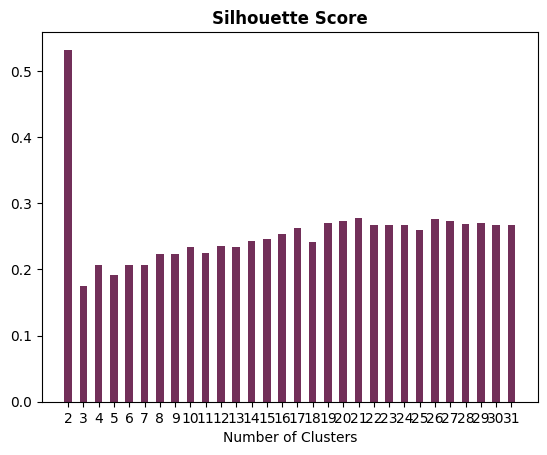

optimum_num_clusters: 2


In [13]:
# candidate values for our number of cluster
parameters = list(range(2, 32))
parameter_grid = ParameterGrid({'n_clusters': parameters})

# sample for silhouette search
rng = np.random.default_rng(42)
n = len(sdf_scaled)
sample_n = min(5000, n)
idx = rng.choice(n, size=sample_n, replace=False)
X_search = sdf_scaled.iloc[idx]

best_score = -1
best_grid = None
silhouette_scores = []

for p in parameter_grid:
    km = KMeans(
        n_clusters=p['n_clusters'],
        n_init=3,
        max_iter=100,
        algorithm="elkan",
        random_state=42
    )
    labels = km.fit_predict(X_search)
    ss = metrics.silhouette_score(
        X_search,
        labels,
        sample_size=min(2000, len(X_search)),
        random_state=42
    )
    silhouette_scores.append(ss)

    print('Parameter:', p, 'Score', ss)
    if ss > best_score:
        best_score = ss
        best_grid = p

# plotting silhouette score
plt.bar(range(len(silhouette_scores)), list(silhouette_scores), align='center', color='#722f59', width=0.5)
plt.xticks(range(len(silhouette_scores)), list(parameters))
plt.title('Silhouette Score', fontweight='bold')
plt.xlabel('Number of Clusters')
plt.show()

optimum_num_clusters = best_grid['n_clusters']
print("optimum_num_clusters:", best_grid['n_clusters'])


In [14]:
# Save the chosen k for kmeans-mark-3, which reads K from this file. Records what k was
# computed on, so kmeans-mark-3 only uses it for the same parquet and fields.
import json, datetime
SILHOUETTE_K_FILE = "silhouette_k.json"
_k = {
    "k":          int(optimum_num_clusters),
    "score":      float(best_score),
    "parquet":    PARQUET_PATH,
    "fields":     list(fields_to_encode),
    "distinct":   bool(DISTINCT),
    "count_cap":  COUNT_CAP if DISTINCT else None,
    "k_range":    [min(parameters), max(parameters)],
    "computed":   datetime.datetime.now().isoformat(timespec="seconds"),
}
with open(SILHOUETTE_K_FILE, "w", encoding="utf-8") as _f:
    json.dump(_k, _f, indent=1)
print(f"wrote k = {_k['k']} (score {_k['score']:.3f}) to {SILHOUETTE_K_FILE}")
if _k["k"] == max(parameters):
    print(f"!! k is the top of the range searched ({min(parameters)}-{max(parameters)}) -- "
          "the best k may be higher, or there may be no natural number of clusters")


wrote k = 2 (score 0.532) to silhouette_k.json


In [15]:
# fitting KMeans
print('Fitting..')
kmeans_n = KMeans(
    n_clusters=optimum_num_clusters,
    n_init=20,
    max_iter=300,
    algorithm="elkan",
    random_state=42
)
kmeans_n.fit(sdf_scaled)
centroids = kmeans_n.cluster_centers_
centroids_pca = pca_2.transform(pd.DataFrame(centroids, columns=sdf_scaled.columns))
print("Optimum number of clusters= " + str(optimum_num_clusters))


Fitting..
Optimum number of clusters= 2


In [16]:
# quick test to measure stability and choose an init number
inertias = []
x_for_kmeans = pca_2_result   # shape (n_samples, 2)

for i in range(5):
    km = KMeans(
        n_clusters=optimum_num_clusters,
        n_init=1,
        random_state=i,
        algorithm="elkan"
    )
    km.fit(x_for_kmeans)
    inertias.append(km.inertia_)

print("Stddev:", np.std(inertias))
print("Mean:", np.mean(inertias))
print("Ratio:", np.std(inertias)/np.mean(inertias))


Stddev: 337.0235194049281
Mean: 15388.184866437232
Ratio: 0.021901447268157098


In [17]:
# another test to measure stability and choose an init number
inertias = []
for i in range(5):
    km = KMeans(
        n_clusters=optimum_num_clusters,
        n_init=10,
        random_state=i,
        algorithm="elkan"
    )
    km.fit(x_for_kmeans)
    inertias.append(km.inertia_)

print("Stddev:", np.std(inertias))
print("Mean:", np.mean(inertias))
print("Ratio:", np.std(inertias)/np.mean(inertias))


Stddev: 0.40019822828502993
Mean: 15188.373033755353
Ratio: 2.6348985990508043e-05
